<sub>**The Annotated ML Handbook** · Part IV: Visualization · by Mahir Absar Khan</sub>

# Chapter 17: Interactive charts with Plotly

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mahir-606/annotated-ml-handbook/blob/main/notebooks/part-4-visualization/17-viz-plotly.ipynb) &nbsp; [📚 Contents](../../book/README.md) &nbsp; [🌐 Web edition](https://mahir-606.github.io/annotated-ml-handbook/)

*Run the setup cell first, then read and run the cells from top to bottom. Every code cell is followed by a table explaining what each line does.*

In [1]:
# Repository setup (not part of the book's examples): run this cell first.
import os, sys
from pathlib import Path

# Files the examples create (CSV, models, figures) go into ./outputs next to the notebook.
OUT = Path.cwd() if Path.cwd().name == "outputs" else Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)
os.chdir(OUT)

# insurance.csv is the practice dataset created in Chapter 11 and reused by later chapters.
# If it is not here yet, copy it from the repository's data/ folder (or download it in Colab).
if not Path("insurance.csv").exists():
    import shutil, urllib.request
    for base in OUT.parents:
        if (base / "data" / "insurance.csv").exists():
            shutil.copy(base / "data" / "insurance.csv", "insurance.csv")
            break
    else:
        try:
            urllib.request.urlretrieve("https://raw.githubusercontent.com/Mahir-606/"
                                       "annotated-ml-handbook/main/data/insurance.csv", "insurance.csv")
        except Exception as e:
            print("Could not fetch insurance.csv; run Chapter 11 first.", e)

# The figure style used in the book.
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.28, "grid.linewidth": 0.6,
    "axes.prop_cycle": cycler(color=["#1f4fff", "#e0245e", "#0f9b62", "#ff6a00",
                                     "#7b3ff2", "#0091b3", "#d99a00", "#d42a2a"]),
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False, "image.cmap": "viridis",
})

# Plotly: interactive in Jupyter/Colab; tools/run_all.py stores static PNGs so GitHub can show them.
try:
    import plotly.io as pio
    pio.renderers.default = os.environ.get("PLOTLY_RENDERER") or (
        "colab" if "google.colab" in sys.modules else "notebook_connected")
except ImportError:
    pass

Plotly draws **interactive** charts: readers can hover to see exact values, zoom, pan, and click legend entries to hide or show series. That makes it ideal for exploring data, for dashboards, and for sharing results as web pages. With a static-image exporter, the same charts become PNG, PDF or SVG files for papers. In the web edition of this book, every chart in this chapter is live; in the PDF, you see the exported image.

> **📖 Definitions**
>
> **Interactive chart**: a chart that responds to the reader, with hover tooltips, zoom, pan and toggling series, usually displayed in a web browser or notebook.
>
> **Plotly Express (`px`)**: Plotly's high-level interface. One function call builds a complete chart from a tidy DataFrame. **Graph objects (`go`)**: the low-level interface for full control and for chart types Express doesn't cover.

> **📝 Note** · **Installation**
>
> `pip install plotly` installs Plotly. To export static images (PNG, PDF, SVG) also run `pip install kaleido`. Recent Kaleido versions use a Chrome or Chromium browser installed on your computer to render images.

## 17.1 Set-up · *Beginner*

**Imports and built-in datasets**

In [2]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
gap = px.data.gapminder()
iris = px.data.iris()
tips = px.data.tips()
print(gap.shape, iris.shape, tips.shape)
print(gap.head(3))

(1704, 8) (150, 6) (244, 7)
       country continent  year  lifeExp       pop   gdpPercap iso_alpha  \
0  Afghanistan      Asia  1952   28.801   8425333  779.445314       AFG   
1  Afghanistan      Asia  1957   30.332   9240934  820.853030       AFG   
2  Afghanistan      Asia  1962   31.997  10267083  853.100710       AFG   

   iso_num  
0        4  
1        4  
2        4  


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>import numpy as np</code></td><td>Arrays.</td></tr>
<tr><td><code>import pandas as pd</code></td><td>Tables.</td></tr>
<tr><td><code>import plotly.express as px</code></td><td>High-level Plotly.</td></tr>
<tr><td><code>import plotly.graph_objects as go</code></td><td>Low-level Plotly.</td></tr>
<tr><td><code>from plotly.subplots import make_subplots</code></td><td>Grids of Plotly charts.</td></tr>
<tr><td><code>gap = px.data.gapminder()</code></td><td>Built-in dataset: countries&#x27; life expectancy, GDP and population, 1952-2007.</td></tr>
<tr><td><code>iris = px.data.iris()</code></td><td>Built-in iris dataset.</td></tr>
<tr><td><code>tips = px.data.tips()</code></td><td>Built-in restaurant tips dataset.</td></tr>
<tr><td><code>print(gap.shape, iris.shape, tips.shape)</code></td><td>These ship with Plotly: no download needed.</td></tr>
<tr><td><code>print(gap.head(3))</code></td><td>A first look at gapminder.</td></tr>
</table>
</details>

Every chart below ends with `fig.show()`. In Jupyter it displays inline; in a script it opens your browser.

## 17.2 Scatter and bubble charts · *Beginner*

**Hover, colour, size and log axis**

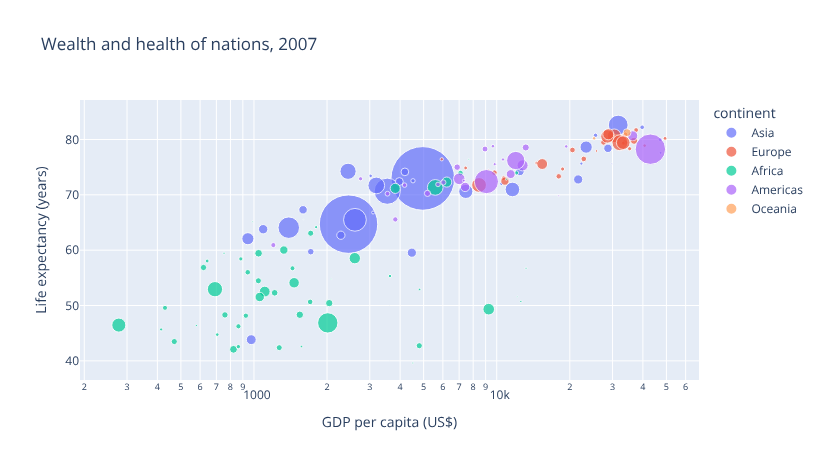

In [3]:
df07 = gap[gap["year"] == 2007]
fig = px.scatter(df07, x="gdpPercap", y="lifeExp", size="pop", color="continent",
                 hover_name="country", log_x=True, size_max=45,
                 labels={"gdpPercap": "GDP per capita (US$)", "lifeExp": "Life expectancy (years)"},
                 title="Wealth and health of nations, 2007", width=820, height=460)
fig.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>df07 = gap[gap[&quot;year&quot;] == 2007]</code></td><td>One year only.</td></tr>
<tr><td><code>fig = px.scatter(df07, x=&quot;gdpPercap&quot;, y=&quot;lifeExp&quot;, size=&quot;pop&quot;, color=&quot;continent&quot;,</code></td><td>One call: x, y, bubble size, colour.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;hover_name=&quot;country&quot;, log_x=True, size_max=45,</code></td><td>Tooltip title; log x-axis; largest bubble size.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;labels={&quot;gdpPercap&quot;: &quot;GDP per capita (US$)&quot;, &quot;lifeExp&quot;: &quot;Life expectancy (years)&quot;},</code></td><td>Readable axis titles.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;title=&quot;Wealth and health of nations, 2007&quot;, width=820, height=460)</code></td><td>Title and size in pixels.</td></tr>
<tr><td><code>fig.show()</code></td><td>Display.</td></tr>
</table>
</details>

### 17.2.1 Animated scatter

**Animation over time**

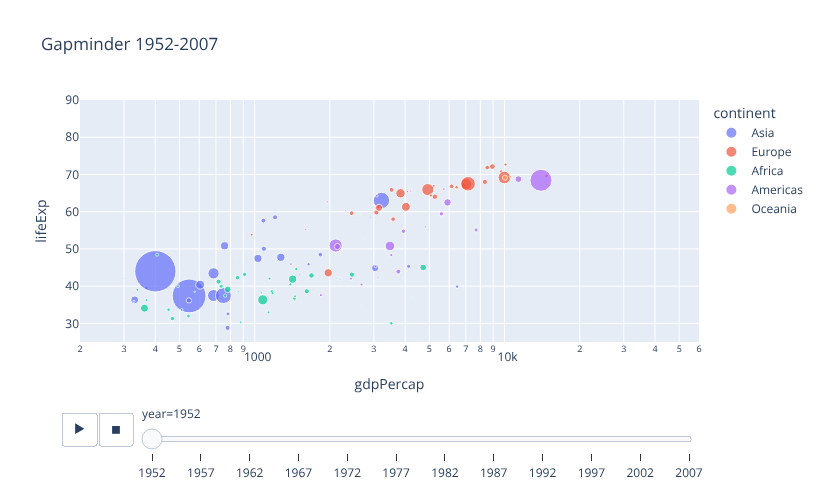

In [4]:
fig = px.scatter(gap, x="gdpPercap", y="lifeExp", size="pop", color="continent", hover_name="country",
                 animation_frame="year", animation_group="country", log_x=True, size_max=45,
                 range_x=[200, 60000], range_y=[25, 90], width=820, height=500,
                 title="Gapminder 1952-2007")
fig.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig = px.scatter(gap, x=&quot;gdpPercap&quot;, y=&quot;lifeExp&quot;, size=&quot;pop&quot;, color=&quot;continent&quot;, hover_name=&quot;country&quot;,</code></td><td>All years this time...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;animation_frame=&quot;year&quot;, animation_group=&quot;country&quot;, log_x=True, size_max=45,</code></td><td>...one animation frame per year; each country keeps its identity.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;range_x=[200, 60000], range_y=[25, 90], width=820, height=500,</code></td><td>Fixed ranges so axes don&#x27;t jump between frames.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;title=&quot;Gapminder 1952-2007&quot;)</code></td><td>Title.</td></tr>
<tr><td><code>fig.show()</code></td><td>Display.</td></tr>
</table>
</details>

## 17.3 Line and area charts · *Beginner*

**Time series with a range slider**

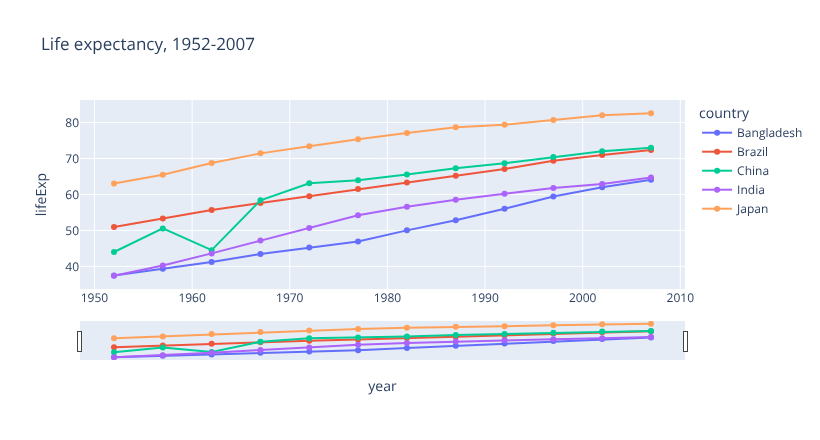

In [5]:
sel = gap[gap["country"].isin(["Bangladesh", "India", "China", "Brazil", "Japan"])]
fig = px.line(sel, x="year", y="lifeExp", color="country", markers=True,
              title="Life expectancy, 1952-2007", width=820, height=440)
fig.update_xaxes(rangeslider_visible=True)
fig.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>sel = gap[gap[&quot;country&quot;].isin([&quot;Bangladesh&quot;, &quot;India&quot;, &quot;China&quot;, &quot;Brazil&quot;, &quot;Japan&quot;])]</code></td><td>Five countries.</td></tr>
<tr><td><code>fig = px.line(sel, x=&quot;year&quot;, y=&quot;lifeExp&quot;, color=&quot;country&quot;, markers=True,</code></td><td>One line per country, with markers.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;title=&quot;Life expectancy, 1952-2007&quot;, width=820, height=440)</code></td><td>Title and size.</td></tr>
<tr><td><code>fig.update_xaxes(rangeslider_visible=True)</code></td><td>Add an interactive range slider below the x-axis.</td></tr>
<tr><td><code>fig.show()</code></td><td>Display.</td></tr>
</table>
</details>

**Stacked area**

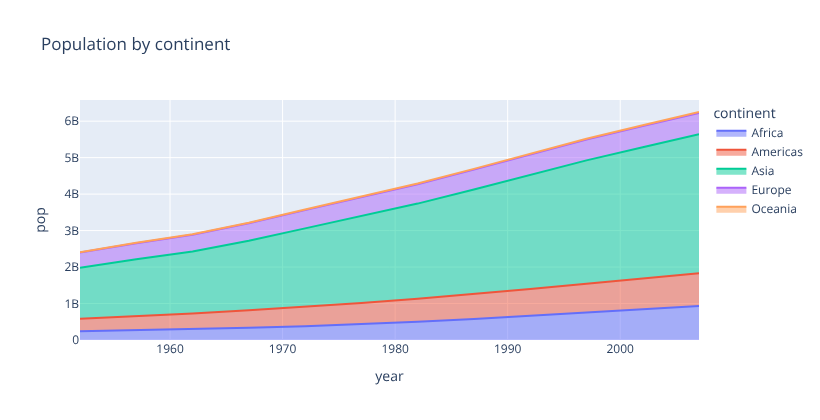

In [6]:
pop = gap.groupby(["year", "continent"], as_index=False)["pop"].sum()
fig = px.area(pop, x="year", y="pop", color="continent",
              title="Population by continent", width=820, height=420)
fig.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>pop = gap.groupby([&quot;year&quot;, &quot;continent&quot;], as_index=False)[&quot;pop&quot;].sum()</code></td><td>Total population per continent and year.</td></tr>
<tr><td><code>fig = px.area(pop, x=&quot;year&quot;, y=&quot;pop&quot;, color=&quot;continent&quot;,</code></td><td>Areas stacked by continent.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;title=&quot;Population by continent&quot;, width=820, height=420)</code></td><td>Title and size.</td></tr>
<tr><td><code>fig.show()</code></td><td>Display.</td></tr>
</table>
</details>

## 17.4 Bar charts · *Beginner*

**Grouped bars with values**

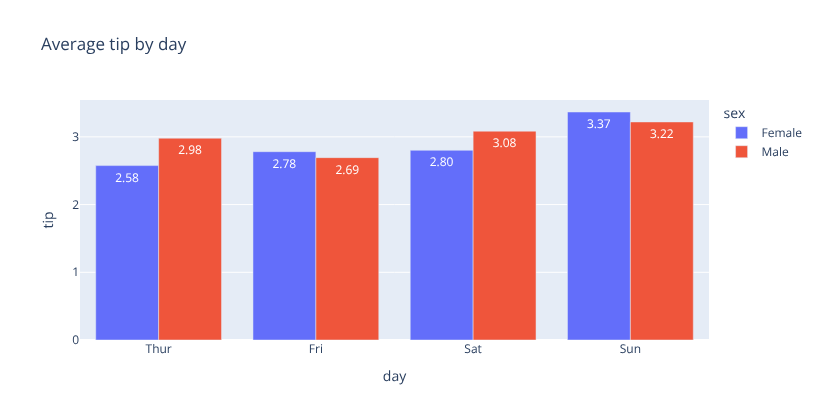

In [7]:
avg = tips.groupby(["day", "sex"], as_index=False)["tip"].mean()
fig = px.bar(avg, x="day", y="tip", color="sex", barmode="group", text_auto=".2f",
             category_orders={"day": ["Thur", "Fri", "Sat", "Sun"]},
             title="Average tip by day", width=820, height=420)
fig.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>avg = tips.groupby([&quot;day&quot;, &quot;sex&quot;], as_index=False)[&quot;tip&quot;].mean()</code></td><td>Mean tip per day and sex.</td></tr>
<tr><td><code>fig = px.bar(avg, x=&quot;day&quot;, y=&quot;tip&quot;, color=&quot;sex&quot;, barmode=&quot;group&quot;, text_auto=&quot;.2f&quot;,</code></td><td>Grouped bars, values to 2 decimals.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;category_orders={&quot;day&quot;: [&quot;Thur&quot;, &quot;Fri&quot;, &quot;Sat&quot;, &quot;Sun&quot;]},</code></td><td>Put the days in calendar order.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;title=&quot;Average tip by day&quot;, width=820, height=420)</code></td><td>Title and size.</td></tr>
<tr><td><code>fig.show()</code></td><td>Display.</td></tr>
</table>
</details>

## 17.5 Distributions · *Beginner*

**Histogram with marginal box plot**

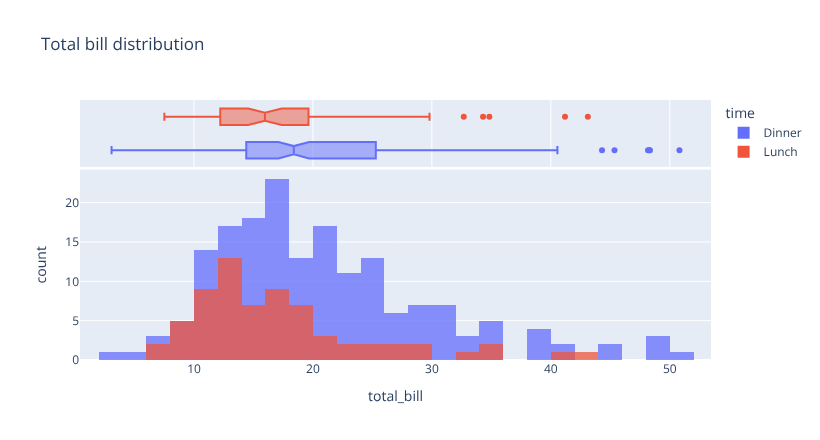

In [8]:
fig = px.histogram(tips, x="total_bill", color="time", nbins=30, marginal="box",
                   opacity=0.75, barmode="overlay",
                   title="Total bill distribution", width=820, height=440)
fig.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig = px.histogram(tips, x=&quot;total_bill&quot;, color=&quot;time&quot;, nbins=30, marginal=&quot;box&quot;,</code></td><td>Histogram plus box plots in the margin.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;opacity=0.75, barmode=&quot;overlay&quot;,</code></td><td>Overlay the two groups semi-transparently.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;title=&quot;Total bill distribution&quot;, width=820, height=440)</code></td><td>Title and size.</td></tr>
<tr><td><code>fig.show()</code></td><td>Display.</td></tr>
</table>
</details>

**Box and violin side by side**

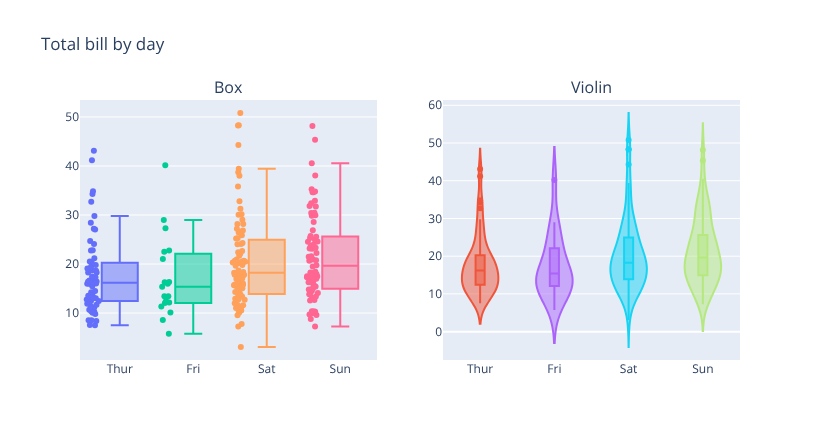

In [9]:
fig = make_subplots(rows=1, cols=2, subplot_titles=("Box", "Violin"))
for day in ["Thur", "Fri", "Sat", "Sun"]:
    d = tips[tips["day"] == day]["total_bill"]
    fig.add_trace(go.Box(y=d, name=day, boxpoints="all", jitter=0.4, showlegend=False), row=1, col=1)
    fig.add_trace(go.Violin(y=d, name=day, box_visible=True, showlegend=False), row=1, col=2)
fig.update_layout(title="Total bill by day", width=820, height=440)
fig.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig = make_subplots(rows=1, cols=2, subplot_titles=(&quot;Box&quot;, &quot;Violin&quot;))</code></td><td>A 1x2 grid of Plotly charts.</td></tr>
<tr><td><code>for day in [&quot;Thur&quot;, &quot;Fri&quot;, &quot;Sat&quot;, &quot;Sun&quot;]:</code></td><td>One trace per day.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;d = tips[tips[&quot;day&quot;] == day][&quot;total_bill&quot;]</code></td><td>That day&#x27;s bills.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;fig.add_trace(go.Box(y=d, name=day, boxpoints=&quot;all&quot;, jitter=0.4, showlegend=False), row=1, col=1)</code></td><td>Box with jittered points.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;fig.add_trace(go.Violin(y=d, name=day, box_visible=True, showlegend=False), row=1, col=2)</code></td><td>Violin with an inner box.</td></tr>
<tr><td><code>fig.update_layout(title=&quot;Total bill by day&quot;, width=820, height=440)</code></td><td>Layout settings for the whole figure.</td></tr>
<tr><td><code>fig.show()</code></td><td>Display.</td></tr>
</table>
</details>

## 17.6 Relationships among many variables · *Intermediate*

**Scatter-plot matrix**

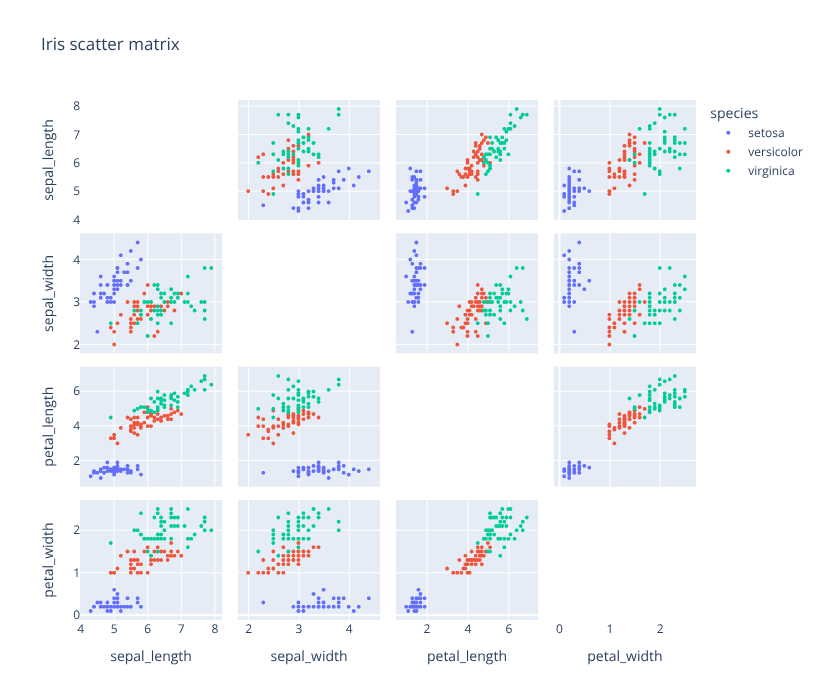

In [10]:
fig = px.scatter_matrix(iris, dimensions=["sepal_length", "sepal_width", "petal_length", "petal_width"],
                        color="species", title="Iris scatter matrix", width=820, height=700)
fig.update_traces(diagonal_visible=False, marker=dict(size=4))
fig.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig = px.scatter_matrix(iris, dimensions=[&quot;sepal_length&quot;, &quot;sepal_width&quot;, &quot;petal_length&quot;, &quot;petal_width&quot;],</code></td><td>Variables to pair.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;color=&quot;species&quot;, title=&quot;Iris scatter matrix&quot;, width=820, height=700)</code></td><td>Colour by species.</td></tr>
<tr><td><code>fig.update_traces(diagonal_visible=False, marker=dict(size=4))</code></td><td>Hide the empty diagonal; smaller markers.</td></tr>
<tr><td><code>fig.show()</code></td><td>Display.</td></tr>
</table>
</details>

> **📖 Definitions**
>
> **Parallel coordinates plot**: each variable gets its own vertical axis, and each observation is a line crossing all the axes. Patterns across many variables show up as bundles of similar lines.

**Parallel coordinates**

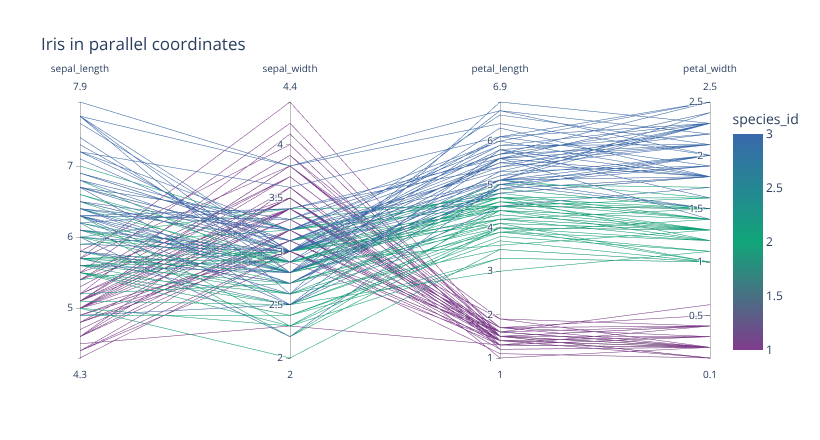

In [11]:
fig = px.parallel_coordinates(iris, dimensions=["sepal_length", "sepal_width", "petal_length", "petal_width"],
                              color="species_id", color_continuous_scale=px.colors.qualitative.Bold[:3],
                              title="Iris in parallel coordinates", width=820, height=440)
fig.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig = px.parallel_coordinates(iris, dimensions=[&quot;sepal_length&quot;, &quot;sepal_width&quot;, &quot;petal_length&quot;, &quot;petal_width&quot;],</code></td><td>One axis per measurement.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;color=&quot;species_id&quot;, color_continuous_scale=px.colors.qualitative.Bold[:3],</code></td><td>Colour by species code.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;title=&quot;Iris in parallel coordinates&quot;, width=820, height=440)</code></td><td>Title and size.</td></tr>
<tr><td><code>fig.show()</code></td><td>Display.</td></tr>
</table>
</details>

## 17.7 Density and heatmaps · *Intermediate*

**2-D density heatmap and contours**

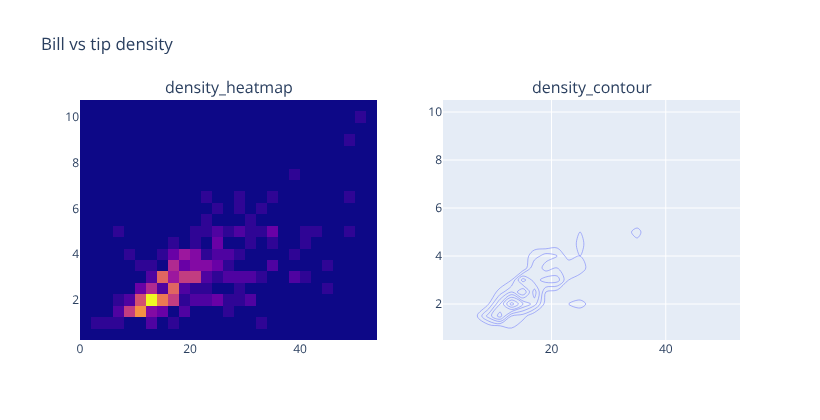

In [12]:
fig = make_subplots(rows=1, cols=2, subplot_titles=("density_heatmap", "density_contour"))
h = px.density_heatmap(tips, x="total_bill", y="tip", nbinsx=25, nbinsy=20)
c = px.density_contour(tips, x="total_bill", y="tip")
fig.add_trace(h.data[0], row=1, col=1)
fig.add_trace(c.data[0], row=1, col=2)
fig.update_layout(title="Bill vs tip density", width=820, height=420, coloraxis_showscale=False)
fig.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig = make_subplots(rows=1, cols=2, subplot_titles=(&quot;density_heatmap&quot;, &quot;density_contour&quot;))</code></td><td>Two panels.</td></tr>
<tr><td><code>h = px.density_heatmap(tips, x=&quot;total_bill&quot;, y=&quot;tip&quot;, nbinsx=25, nbinsy=20)</code></td><td>A full Express figure...</td></tr>
<tr><td><code>c = px.density_contour(tips, x=&quot;total_bill&quot;, y=&quot;tip&quot;)</code></td><td>...and another one.</td></tr>
<tr><td><code>fig.add_trace(h.data[0], row=1, col=1)</code></td><td>Copy each figure&#x27;s trace into the grid.</td></tr>
<tr><td><code>fig.add_trace(c.data[0], row=1, col=2)</code></td><td>Second trace.</td></tr>
<tr><td><code>fig.update_layout(title=&quot;Bill vs tip density&quot;, width=820, height=420, coloraxis_showscale=False)</code></td><td>Hide the colour bar for a cleaner grid.</td></tr>
<tr><td><code>fig.show()</code></td><td>Display.</td></tr>
</table>
</details>

**Annotated heatmap with imshow**

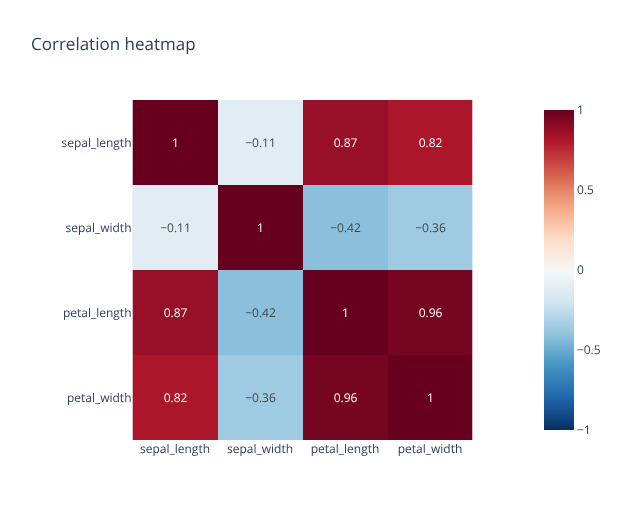

In [13]:
corr = iris[["sepal_length", "sepal_width", "petal_length", "petal_width"]].corr().round(2)
fig = px.imshow(corr, text_auto=True, color_continuous_scale="RdBu_r", zmin=-1, zmax=1,
                title="Correlation heatmap", width=620, height=520)
fig.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>corr = iris[[&quot;sepal_length&quot;, &quot;sepal_width&quot;, &quot;petal_length&quot;, &quot;petal_width&quot;]].corr().round(2)</code></td><td>4x4 correlations.</td></tr>
<tr><td><code>fig = px.imshow(corr, text_auto=True, color_continuous_scale=&quot;RdBu_r&quot;, zmin=-1, zmax=1,</code></td><td>Diverging colours, fixed scale, values in cells.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;title=&quot;Correlation heatmap&quot;, width=620, height=520)</code></td><td>Title and size.</td></tr>
<tr><td><code>fig.show()</code></td><td>Display.</td></tr>
</table>
</details>

## 17.8 Parts of a whole · *Beginner*

> **📖 Definitions**
>
> **Sunburst chart**: nested rings showing a hierarchy, with the centre as the root and each outer ring splitting its parent into parts. **Treemap**: the same hierarchy shown as nested rectangles whose areas are proportional to the values.

**Pie, sunburst and treemap**

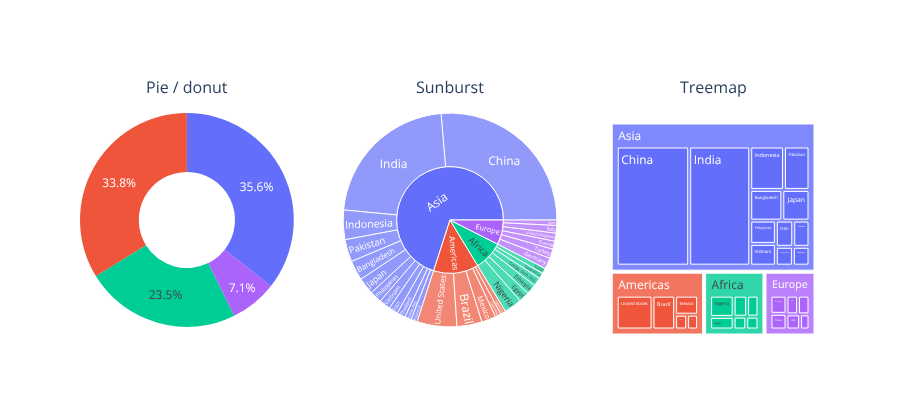

In [14]:
fig = make_subplots(rows=1, cols=3, specs=[[{"type": "domain"}] * 3],
                    subplot_titles=("Pie / donut", "Sunburst", "Treemap"))
by_day = tips.groupby("day", as_index=False)["tip"].sum()
fig.add_trace(go.Pie(labels=by_day["day"], values=by_day["tip"], hole=0.45), row=1, col=1)
big = df07[df07["pop"] > 4e7]
sb = px.sunburst(big, path=["continent", "country"], values="pop")
tm = px.treemap(big, path=["continent", "country"], values="pop")
fig.add_trace(sb.data[0], row=1, col=2)
fig.add_trace(tm.data[0], row=1, col=3)
fig.update_layout(width=900, height=420, showlegend=False)
fig.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig = make_subplots(rows=1, cols=3, specs=[[{&quot;type&quot;: &quot;domain&quot;}] * 3],</code></td><td>&quot;domain&quot; subplots hold pie-like charts.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;subplot_titles=(&quot;Pie / donut&quot;, &quot;Sunburst&quot;, &quot;Treemap&quot;))</code></td><td>Titles.</td></tr>
<tr><td><code>by_day = tips.groupby(&quot;day&quot;, as_index=False)[&quot;tip&quot;].sum()</code></td><td>Total tips per day.</td></tr>
<tr><td><code>fig.add_trace(go.Pie(labels=by_day[&quot;day&quot;], values=by_day[&quot;tip&quot;], hole=0.45), row=1, col=1)</code></td><td>hole makes it a donut.</td></tr>
<tr><td><code>big = df07[df07[&quot;pop&quot;] &gt; 4e7]</code></td><td>Only countries with more than 40 million people.</td></tr>
<tr><td><code>sb = px.sunburst(big, path=[&quot;continent&quot;, &quot;country&quot;], values=&quot;pop&quot;)</code></td><td>path = hierarchy levels from the centre outwards.</td></tr>
<tr><td><code>tm = px.treemap(big, path=[&quot;continent&quot;, &quot;country&quot;], values=&quot;pop&quot;)</code></td><td>Same hierarchy as rectangles.</td></tr>
<tr><td><code>fig.add_trace(sb.data[0], row=1, col=2)</code></td><td>Copy the sunburst into the grid.</td></tr>
<tr><td><code>fig.add_trace(tm.data[0], row=1, col=3)</code></td><td>Copy the treemap.</td></tr>
<tr><td><code>fig.update_layout(width=900, height=420, showlegend=False)</code></td><td>Size; no legend.</td></tr>
<tr><td><code>fig.show()</code></td><td>Display.</td></tr>
</table>
</details>

## 17.9 Flows: the Sankey diagram · *Intermediate*

> **📖 Definitions**
>
> **Sankey diagram**: nodes connected by bands whose widths are proportional to the flow between them. It shows how quantities move or split between stages.

**Where did the data go?**

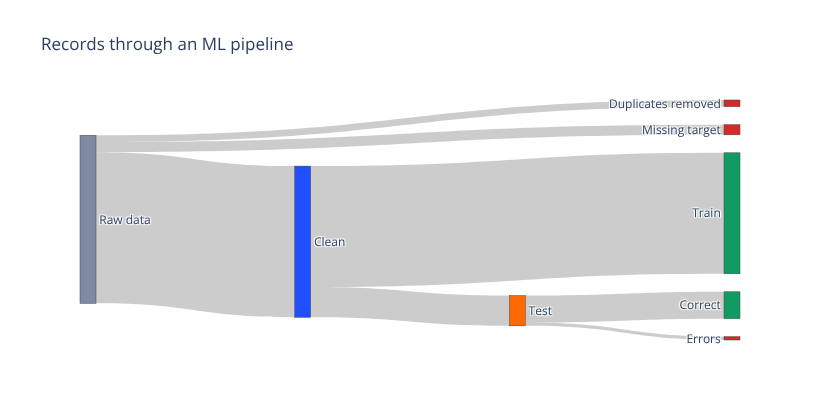

In [15]:
labels = ["Raw data", "Duplicates removed", "Missing target", "Clean", "Train", "Test", "Correct", "Errors"]
source = [0, 0, 0, 3, 3, 5, 5]
target = [1, 2, 3, 4, 5, 6, 7]
value = [40, 60, 900, 720, 180, 160, 20]
fig = go.Figure(go.Sankey(node=dict(label=labels, pad=18, thickness=16,
                                    color=["#7f8aa3", "#d42a2a", "#d42a2a", "#1f4fff", "#0f9b62", "#ff6a00", "#0f9b62", "#d42a2a"]),
                          link=dict(source=source, target=target, value=value)))
fig.update_layout(title="Records through an ML pipeline", width=820, height=420)
fig.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>labels = [&quot;Raw data&quot;, &quot;Duplicates removed&quot;, &quot;Missing target&quot;, &quot;Clean&quot;, &quot;Train&quot;, &quot;Test&quot;, &quot;Correct&quot;, &quot;Errors&quot;]</code></td><td>Node names (index 0..7).</td></tr>
<tr><td><code>source = [0, 0, 0, 3, 3, 5, 5]</code></td><td>Each band starts at this node index...</td></tr>
<tr><td><code>target = [1, 2, 3, 4, 5, 6, 7]</code></td><td>...and ends at this one.</td></tr>
<tr><td><code>value = [40, 60, 900, 720, 180, 160, 20]</code></td><td>Records flowing along each band.</td></tr>
<tr><td><code>fig = go.Figure(go.Sankey(node=dict(label=labels, pad=18, thickness=16,</code></td><td>Node settings: labels, spacing, bar width.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;link=dict(source=source, target=target, value=value)))</code></td><td>The flows.</td></tr>
<tr><td><code>fig.update_layout(title=&quot;Records through an ML pipeline&quot;, width=820, height=420)</code></td><td>Title and size.</td></tr>
<tr><td><code>fig.show()</code></td><td>Display.</td></tr>
</table>
</details>

## 17.10 3-D charts · *Intermediate*

**Rotatable 3-D scatter and surface**

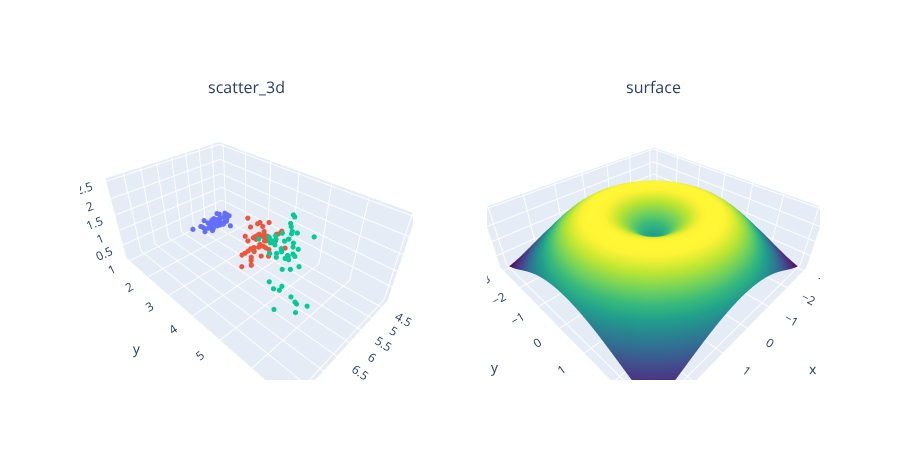

In [16]:
fig = make_subplots(rows=1, cols=2, specs=[[{"type": "scene"}, {"type": "scene"}]],
                    subplot_titles=("scatter_3d", "surface"))
s3 = px.scatter_3d(iris, x="sepal_length", y="petal_length", z="petal_width", color="species")
for tr in s3.data:
    tr.marker.size = 3
    fig.add_trace(tr, row=1, col=1)
xg = np.linspace(-3, 3, 50)
Z = np.sin(np.sqrt(xg[:, None] ** 2 + xg[None, :] ** 2))
fig.add_trace(go.Surface(x=xg, y=xg, z=Z, colorscale="Viridis", showscale=False), row=1, col=2)
fig.update_layout(width=900, height=460, showlegend=False)
fig.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig = make_subplots(rows=1, cols=2, specs=[[{&quot;type&quot;: &quot;scene&quot;}, {&quot;type&quot;: &quot;scene&quot;}]],</code></td><td>&quot;scene&quot; subplots are 3-D.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;subplot_titles=(&quot;scatter_3d&quot;, &quot;surface&quot;))</code></td><td>Titles.</td></tr>
<tr><td><code>s3 = px.scatter_3d(iris, x=&quot;sepal_length&quot;, y=&quot;petal_length&quot;, z=&quot;petal_width&quot;, color=&quot;species&quot;)</code></td><td>3-D scatter coloured by species.</td></tr>
<tr><td><code>for tr in s3.data:</code></td><td>One trace per species...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;tr.marker.size = 3</code></td><td>...with small markers...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;fig.add_trace(tr, row=1, col=1)</code></td><td>...copied into the left panel.</td></tr>
<tr><td><code>xg = np.linspace(-3, 3, 50)</code></td><td>Grid values.</td></tr>
<tr><td><code>Z = np.sin(np.sqrt(xg[:, None] ** 2 + xg[None, :] ** 2))</code></td><td>z = sin(distance from centre), via broadcasting.</td></tr>
<tr><td><code>fig.add_trace(go.Surface(x=xg, y=xg, z=Z, colorscale=&quot;Viridis&quot;, showscale=False), row=1, col=2)</code></td><td>The surface.</td></tr>
<tr><td><code>fig.update_layout(width=900, height=460, showlegend=False)</code></td><td>Size.</td></tr>
<tr><td><code>fig.show()</code></td><td>Display.</td></tr>
</table>
</details>

## 17.11 Maps · *Intermediate*

Plotly draws maps with `px.choropleth` (regions coloured by value), `px.scatter_geo` (points on a map) and tile maps. The country outlines are downloaded by the browser when the chart is displayed, so maps need an internet connection.

**A choropleth world map (needs internet when displayed)**

*Shown for reference, not run automatically (it waits for input, needs your own files, or would change your system). Copy it into a cell to try it.*

```python
fig = px.choropleth(df07, locations="iso_alpha", color="lifeExp",
                    hover_name="country", color_continuous_scale="Viridis",
                    title="Life expectancy, 2007")
fig.show()
```

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig = px.choropleth(df07, locations=&quot;iso_alpha&quot;, color=&quot;lifeExp&quot;,</code></td><td>iso_alpha holds 3-letter country codes such as BGD.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;hover_name=&quot;country&quot;, color_continuous_scale=&quot;Viridis&quot;,</code></td><td>Tooltip and colour scale.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;title=&quot;Life expectancy, 2007&quot;)</code></td><td>Title.</td></tr>
<tr><td><code>fig.show()</code></td><td>Display in the browser.</td></tr>
</table>
</details>

## 17.12 Customising and exporting Plotly charts · *Beginner*

**Templates, fonts, annotations and export**

In [17]:
fig = px.scatter(df07, x="gdpPercap", y="lifeExp", color="continent", log_x=True,
                 template="simple_white", width=700, height=420)
fig.update_layout(font=dict(family="Arial", size=13),
                  title=dict(text="Richer countries live longer", x=0.02),
                  legend=dict(orientation="h", y=-0.2))
fig.add_annotation(x=np.log10(42951.65), y=78.24, text="USA", showarrow=True)
fig.write_image("lifeexp.png", width=700, height=420, scale=3)
fig.write_image("lifeexp.pdf")
fig.write_image("lifeexp.svg")
fig.write_html("lifeexp.html", include_plotlyjs="cdn")
from pathlib import Path
print({f: f"{Path(f).stat().st_size // 1024} KB" for f in ["lifeexp.png", "lifeexp.pdf", "lifeexp.svg", "lifeexp.html"]})

{'lifeexp.png': '174 KB', 'lifeexp.pdf': '15 KB', 'lifeexp.svg': '38 KB', 'lifeexp.html': '14 KB'}


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig = px.scatter(df07, x=&quot;gdpPercap&quot;, y=&quot;lifeExp&quot;, color=&quot;continent&quot;, log_x=True,</code></td><td>A base chart...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;template=&quot;simple_white&quot;, width=700, height=420)</code></td><td>...using a clean built-in template.</td></tr>
<tr><td><code>fig.update_layout(font=dict(family=&quot;Arial&quot;, size=13),</code></td><td>Font for the whole figure.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;title=dict(text=&quot;Richer countries live longer&quot;, x=0.02),</code></td><td>Left-aligned title stating the finding.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;legend=dict(orientation=&quot;h&quot;, y=-0.2))</code></td><td>Horizontal legend below the chart.</td></tr>
<tr><td><code>fig.add_annotation(x=np.log10(42951.65), y=78.24, text=&quot;USA&quot;, showarrow=True)</code></td><td>On a log axis, x positions are given as log10 values.</td></tr>
<tr><td><code>fig.write_image(&quot;lifeexp.png&quot;, width=700, height=420, scale=3)</code></td><td>PNG at 3x resolution (2100 px wide): sharp for print.</td></tr>
<tr><td><code>fig.write_image(&quot;lifeexp.pdf&quot;)</code></td><td>Vector PDF for papers and LaTeX.</td></tr>
<tr><td><code>fig.write_image(&quot;lifeexp.svg&quot;)</code></td><td>Vector SVG.</td></tr>
<tr><td><code>fig.write_html(&quot;lifeexp.html&quot;, include_plotlyjs=&quot;cdn&quot;)</code></td><td>A standalone interactive web page (loads Plotly from the internet).</td></tr>
<tr><td><code>from pathlib import Path</code></td><td>Check the files.</td></tr>
<tr><td><code>print({f: f&quot;{Path(f).stat().st_size // 1024} KB&quot; for f in [&quot;lifeexp.png&quot;, &quot;lifeexp.pdf&quot;, &quot;lifeexp.svg&quot;, &quot;lifeexp.html&quot;]})</code></td><td>Sizes.</td></tr>
</table>
</details>

| Plotly method | Produces | Use for |
|---|---|---|
| `fig.write_image("f.png", scale=3)` | raster image | Word, PowerPoint, Google Docs |
| `fig.write_image("f.pdf")` / `"f.svg"` | vector image | journals, LaTeX, posters |
| `fig.write_html("f.html")` | interactive web page | sharing, supplementary material, websites |
| `fig.to_json()` / `pio.from_json()` | the figure's data | saving and reloading figures exactly |

| Template | Look |
|---|---|
| `"plotly"` | the default, light blue-grey background |
| `"plotly_white"`, `"simple_white"` | white backgrounds, good for papers |
| `"plotly_dark"` | dark background for slides |
| `"ggplot2"`, `"seaborn"` | mimic those libraries' styles |

> **🐞 Bug hunt** · **`ValueError: Image export using the "kaleido" engine requires the kaleido package`**
>
> Install it with `pip install kaleido` into the same environment. Recent versions also need Chrome or Chromium installed; if it can't find a browser, run `plotly_get_chrome` (installed with Kaleido) or install Chrome. A blank chart in Jupyter usually means the notebook renderer isn't set up: try `import plotly.io as pio; pio.renderers.default = "notebook"` (or `"browser"`).

> **✍️ Try it yourself**
>
> 1. Make an animated bar chart of the five most populous countries' life expectancy over time (`animation_frame="year"`).
> 2. Draw a sunburst of `tips` by `day`, then `time`, then `sex`, with `values="tip"`.
> 3. Export one chart as a 300-dpi-equivalent PNG for a 7-inch-wide figure (hint: `width=700, scale=3`).
>
> *Worked solutions:* [solutions-parts-1-4.ipynb](../../solutions/solutions-parts-1-4.ipynb), section *Chapter 17*.

---

⬅️ [Chapter 16: The Seaborn chart gallery](16-viz-seaborn-gallery.ipynb) · [📚 Contents](../../book/README.md) · [Chapter 18: Figures for papers, theses and assignments](18-viz-export.ipynb) ➡️